# Stream quality check

Is the recorded EMG stream good, noisy or disturbed, and by what? This notebook reads a session
folder written by `emgacq` (protocol session, free recording, or a session that crashed) and
checks it in three layers:

1. **Link**: did every sample arrive? Sample rate, lost packets, gaps, reconnections, invalid rows.
2. **Each channel**: electrode contact (offset, drift, pops, railing, flat), interference at rest
   (50 Hz mains, noise floor, low-frequency movement artifacts) and how clearly the EMG of the
   gestures stands out of the rest level.
3. **When**: a second-by-second timeline of what disturbed each channel.

It ends with a verdict (**GOOD** usable as it is, **WARN** usable but look at the flagged items,
**BAD** fix the setup before recording more) and concrete advice for each problem found.

**How to use it.** Open it in VS Code (or Jupyter) with the kernel of the repository's `.venv`,
set `FOLDER` in the next-but-one cell (leave `None` for the latest session) and *Run All*.
Nothing is written to the session folder. The same checks without plots:
`python -m tools.stream_quality [data/<folder>]` (from `DataAquisitionNoCamera/`), or
`--all` for one line per session.

The thresholds are first guesses from the first Cyton sessions of 2026-10-21; they are listed
below and can be overridden per run.

In [25]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# the notebook lives in DataAquisitionNoCamera/tools: make the emgacq and tools packages importable
here = Path.cwd()
ROOT = next(p for p in [here, *here.parents, here / "DataAquisitionNoCamera"] if (p / "emgacq").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools import stream_quality as sq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

sessions = sq.list_sessions()
pd.DataFrame({"session": [p.name for p in sessions],
              "modified": [pd.Timestamp((p / "emg.csv").stat().st_mtime, unit="s").tz_localize("UTC")
                           .tz_convert("Europe/Rome").strftime("%Y-%m-%d %H:%M") for p in sessions],
              "emg.csv MB": [round((p / "emg.csv").stat().st_size / 1e6, 1) for p in sessions]}).tail(12)

,session,modified,emg.csv MB
0,DEMO_S1_2026-10-01_2138,2026-10-01 21:47,16.5
1,TEST_S1_2026-10-21_1650,2026-10-21 16:53,3.7
2,TEST_S1_2026-10-21_1707,2026-10-21 17:09,3.3
3,TEST_S1_2026-10-21_1747,2026-10-21 17:48,1.8
4,TEST_S1_2026-10-21_1756,2026-10-21 17:58,3.3
5,TEST_S1_FREE_2026-10-28_1900,2026-10-28 19:01,1.3
6,TEST_S2_FREE_2026-11-04_1850,2026-11-04 18:52,2.6
7,TEST2_S2_2026-11-04_1854,2026-11-04 19:04,13.2
8,TEST3_S2_2026-11-04_1920,2026-11-04 19:29,11.9


## 1. Session and verdict

`FOLDER`: a folder name inside `data/`, a full path, or `None` for the most recent session.
`THRESHOLDS`: overrides of the defaults shown in the table below (e.g. `{"mains_bad_uv": 80}`).
The printed report is the whole answer in text form; the sections after it show where each
number comes from.

In [26]:
FOLDER = None
THRESHOLDS = {}

folder = sq.latest_session() if FOLDER is None else (
    Path(FOLDER) if Path(FOLDER).is_absolute() else sq.data_dir() / FOLDER)
rec = sq.load(folder, THRESHOLDS)
rep = sq.analyze(rec)
print(sq.report_text(rep))

Session TEST3_S2_2026-11-04_1920  (completed, protocol)
VERDICT: BAD - poor stream: fix the setup before recording more

Link: GOOD
  133302 samples, 532.4 s, 250.39 samples/s (nominal 250), 1 segment(s)
  lost 0 (0.000%) in 0 events, 0 duplicates, 0 all-zero rows, 0 gaps (0 s), 0 reconnections
Quality check in the app: NOT_JUDGED (1 attempt(s))
Trials: 36 complete, 0 bad, 0 repeated

Channels (rest: labelled rest, 179.5 s):
  channel status  dc_mV  wander_uV  pops  mains_rest_uV  noise_rest_uV  lowfreq_rest_uV best_gesture  snr_best
      ch1    BAD  -3.29     1214.7     1         1236.2          25.67            324.3        CLOSE       0.6
      ch2    BAD  -0.14     2027.0     0         1063.4          20.51            233.1        CLOSE       0.6
      ch3    BAD   4.89     1838.1     0           89.8          12.63             50.6         OPEN       2.8
      ch4    BAD   1.51     1388.3     0          621.4          13.40            144.8         OPEN       1.1
  ch1 WARN: base

In [27]:
# thresholds in use (WARN above the first value, BAD above the second; SNR: below)
pd.DataFrame([{"setting": k, "value": v} for k, v in rec.th.items()]).set_index("setting").T

setting,mains_hz,split_gap_s,loss_warn_pct,loss_bad_pct,rate_tol_pct,dc_warn_frac,dc_bad_frac,railed_level,railed_bad_frac,flat_std_uv,flat_bad_frac,pop_uv,pop_warn_per_min,pop_bad_per_min,wander_warn_uv,wander_bad_uv,mains_warn_uv,mains_bad_uv,noise_warn_uv,noise_bad_uv,lowfreq_warn_uv,lowfreq_bad_uv,snr_warn,snr_bad,corr_warn,window_s,rest_settle_s,active_settle_s,min_rest_s
value,50.0,0.5,0.1,1.0,2.0,0.25,0.8,0.9,0.001,0.5,0.05,1000.0,1.0,5.0,1000.0,5000.0,15.0,50.0,5.0,10.0,20.0,50.0,3.0,1.5,0.6,1.0,1.0,0.5,4.0


## 2. Link

The plot counts the samples that arrived in each second. A healthy Cyton link sits flat on the
nominal 250 samples/s. Dips mean lost packets (red triangles; the package counter of the board
skipped numbers), a drop to zero with hatching is a gap (no data at all, e.g. while
reconnecting). Packet loss below 0.1% is negligible; above 1% the data have holes that matter for
the features. After a reconnection the board restarts: the counter starts again from 0, the
electrode offsets jump, and the first sample can be an invalid all-zero row. This notebook cuts
the stream into **segments** at every gap or invalid row and filters each segment on its own,
so these jumps do not leak into the metrics.

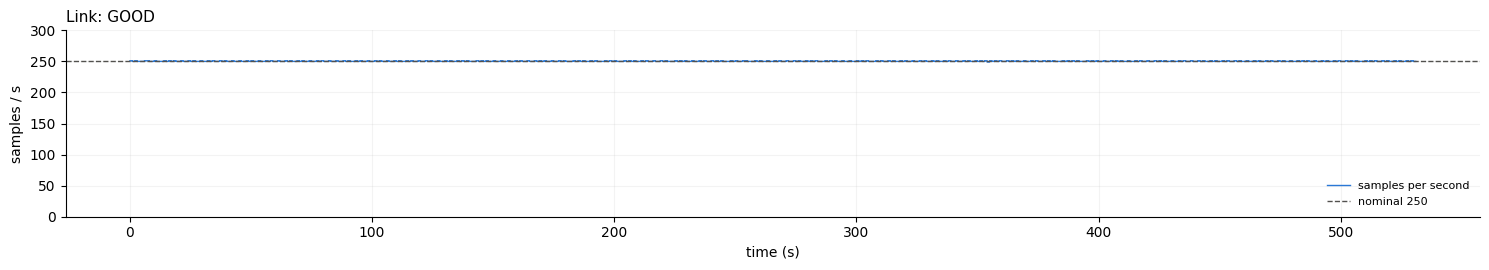

In [28]:
sq.plot_link(rep)
plt.show()
if rep.link["gaps"]:
    display(pd.DataFrame(rep.link["gaps"]))

## 3. Signals

**Raw** (each segment's median removed): what the amplifier saw. Look for slow drifts and steps
(electrode settling, cables pulled), spikes (pops: an electrode losing contact for an instant)
and traces stuck at a constant value (flat) or at the edge of the range (railed). The Cyton is
DC-coupled, so slow drifts of a few hundred µV are normal; the band-pass removes them.

**Filtered** (20-120 Hz band-pass, 50/100 Hz notched): the EMG band. At rest the trace should
be a thin band of a few µV; during the gestures (coloured bands) it should widen clearly. Cues
are light grey, pauses darker grey, gaps hatched in red. After a reconnection the board
restarts and the baseline needs about 10 s to settle (the exponential drift after the gap).

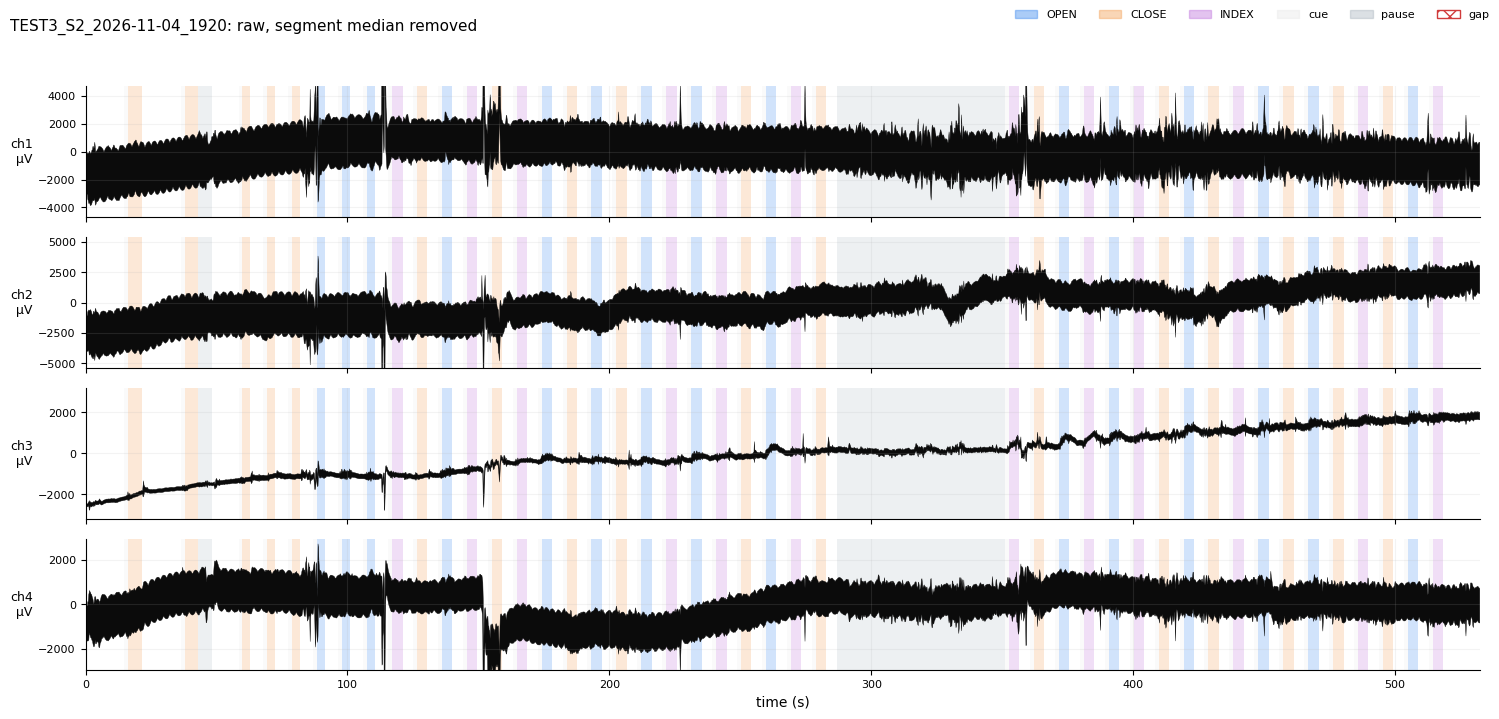

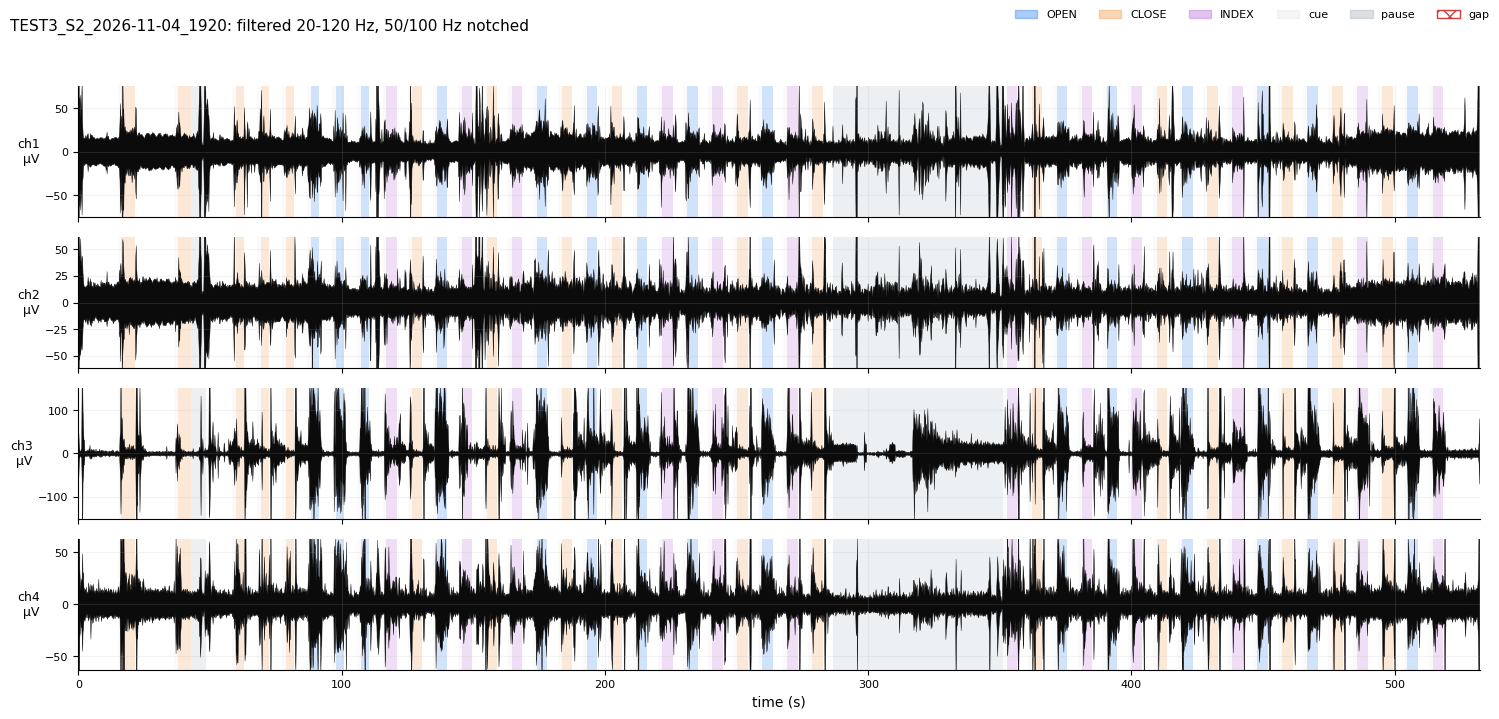

In [29]:
sq.plot_signals(rec, "raw")
plt.show()
sq.plot_signals(rec, "emg")
plt.show()

## 4. Noise at rest

At rest the muscles are silent, so whatever is left is noise. Three numbers per channel:

- **Mains (50 Hz)**: the amplitude of the narrow 50 Hz line above the local floor. The mains
  field reaches both electrodes of a pair almost equally, and a bipolar channel subtracts
  them, so it cancels only if the two electrodes have similar contact impedance. A large 50 Hz
  level therefore points to a poor or unequal contact (or a bad BIAS/reference electrode), even
  though the notch filter removes the line itself offline.
- **Noise floor**: RMS in the EMG band with the mains notched. This is the level the EMG has to
  rise above. With good gel electrodes it is around 1-5 µV.
- **Low-frequency (1-15 Hz)**: movement, cable sway, sweat. It sits below the EMG band, but large
  values mean the electrodes or cables move.

In the spectrum, the rest curve (blue) should be low and fairly flat in the shaded EMG band,
with at most a narrow peak at 50 Hz; the gesture curve (orange) should lie well above it across
20-120 Hz. Narrow peaks at other frequencies are listed as "other interference" (switching power
supplies, chargers, displays).

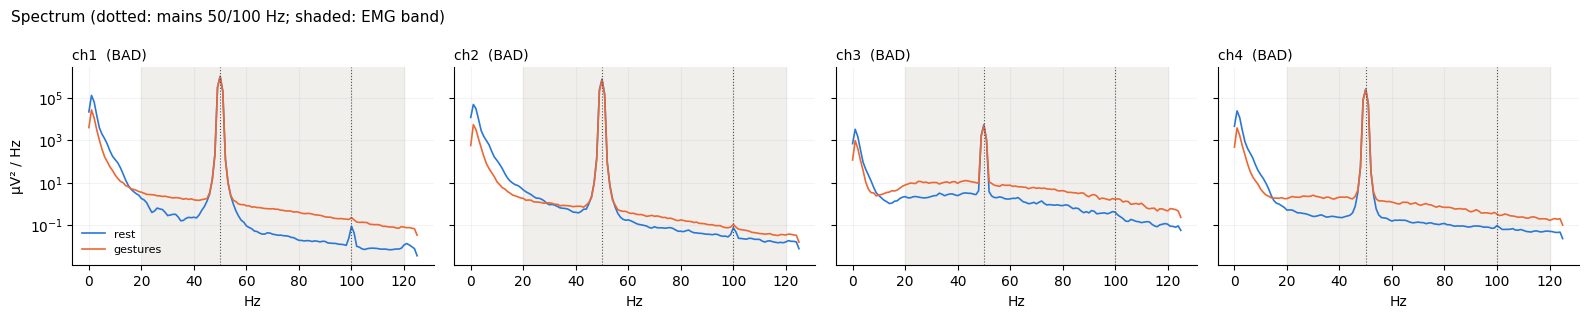

,channel,status,mains_rest_uV,mains100_rest_uV,noise_rest_uV,lowfreq_rest_uV,dc_mV,wander_uV,pops,railed_pct,flat_pct
0,ch1,BAD,1236.2,0.4,25.67,324.3,-3.29,1214.7,1,0.0,0.0
1,ch2,BAD,1063.4,0.3,20.51,233.1,-0.14,2027.0,0,0.0,0.0
2,ch3,BAD,89.8,0.7,12.63,50.6,4.89,1838.1,0,0.0,0.0
3,ch4,BAD,621.4,0.1,13.40,144.8,1.51,1388.3,0,0.0,0.0


rest used: labelled rest, 179.5 s


,channel,freq_hz,above_floor_db,rms_uv,source
0,ch1,50.0,48.5,1236.07,mains
1,ch2,50.0,48.8,1063.27,mains
2,ch4,50.0,48.7,621.31,mains
3,ch3,50.0,32.3,89.81,mains


In [30]:
sq.plot_psd(rep)
plt.show()
display(rep.channels[["channel", "status", "mains_rest_uV", "mains100_rest_uV", "noise_rest_uV",
                      "lowfreq_rest_uV", "dc_mV", "wander_uV", "pops", "railed_pct", "flat_pct"]])
print(f"rest used: {rep.rest_source}, {rep.rest_s} s")
if len(rep.spurs):
    display(rep.spurs.head(12))

## 5. EMG content

The envelope is the moving RMS (250 ms) of the filtered signal: it should rise inside the
gesture bands and fall back in the rests. The bar chart compares, per channel, the RMS at rest
with the RMS of each gesture; the ratio of the strongest gesture to rest is the channel's
signal-to-noise ratio (`snr_best`). Below about 3 the gestures barely show on that channel:
either the electrodes are not over a muscle that works in these gestures, or the contact adds
so much noise that the EMG drowns. A channel can legitimately stay quiet for one gesture (an
extensor during CLOSE), which is why the best gesture is used. A free recording has no labels:
its loudest 10% of seconds stand in for "gestures" and the quietest 20% for rest.

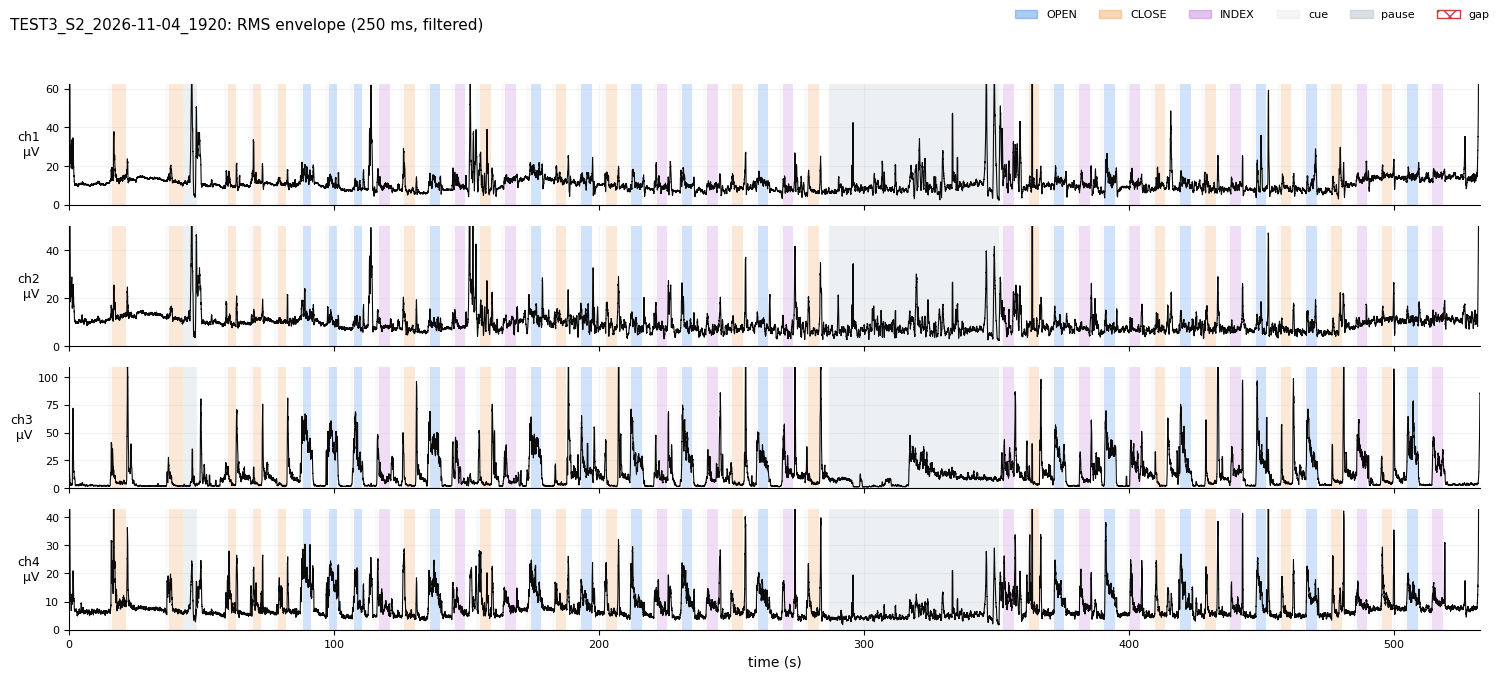

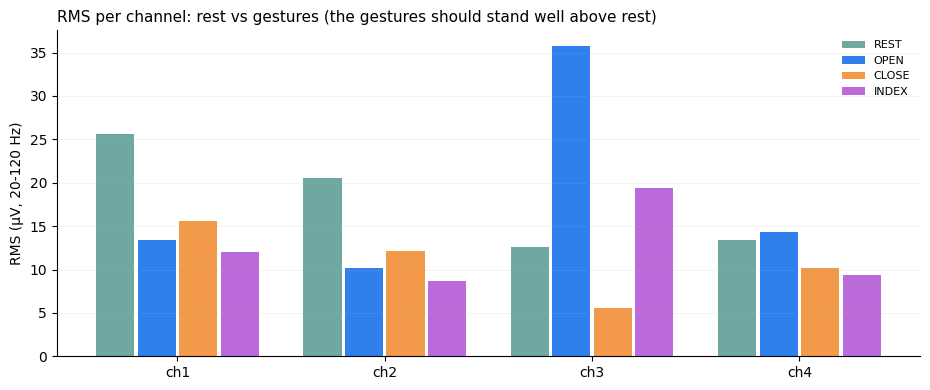

,ch1,ch2,ch3,ch4
REST,25.7,20.5,12.6,13.4
OPEN,13.4,10.1,35.8,14.3
CLOSE,15.6,12.1,5.5,10.2
INDEX,12.0,8.7,19.4,9.4


,trial_id,block,gesture,attempts,hold_s,bad,complete
0,1,1,INDEX,1,4.01,False,True
1,2,1,CLOSE,1,4.01,False,True
2,3,1,OPEN,1,4.01,False,True
3,4,1,INDEX,1,4.01,False,True
4,5,1,CLOSE,1,4.01,False,True
5,6,1,INDEX,1,4.01,False,True
6,7,1,OPEN,1,4.01,False,True
7,8,1,CLOSE,1,4.01,False,True
8,9,1,OPEN,1,4.01,False,True
9,10,1,CLOSE,1,4.01,False,True


In [31]:
sq.plot_envelope(rec)
plt.show()
sq.plot_gesture_rms(rep)
plt.show()
display(rep.gesture_rms.round(1))
if rep.trials is not None and len(rep.trials):
    display(rep.trials)

## 6. Correlation between channels at rest

Different electrode pairs over different muscles should be largely independent at rest
(|r| well below 0.5). The most common reason they are not is a common-mode signal: the whole
arm picks up mains and other noise, the BIAS electrode is meant to hold that common level down,
and each bipolar channel cancels what is left only as far as its two electrodes have equal
contact impedance. With a weak BIAS, every unbalanced pair lets part of the same common signal
through, so channels with no electrode in common become correlated; the sign (+ or -) only tells
which electrode of each pair has the higher impedance. Such a pattern changes whenever the
electrodes are re-applied. A pair that correlates in every session, whatever the contact, points
instead to the wiring, or to gel bridging two sites.

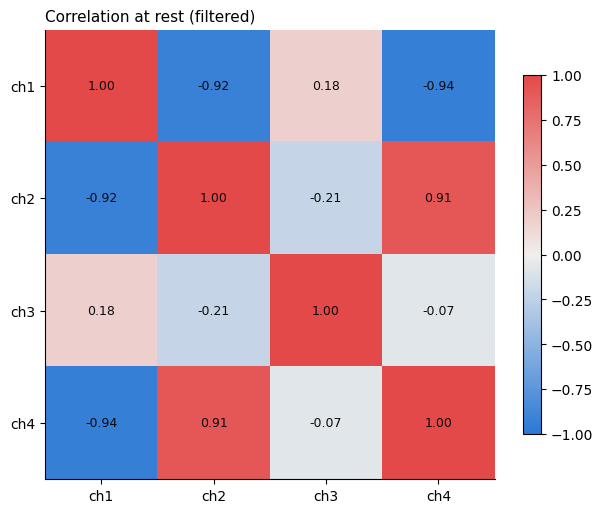

In [32]:
fig = sq.plot_corr(rep)
plt.show() if fig is not None else print("not enough rest data for a correlation")

## 7. Timeline: what disturbs each channel, and when

Every channel is split into 1 s windows, and each window gets the most serious problem it shows
(from worst to mildest: railed, flat, pop, low-freq, mains, noisy; otherwise ok). "noisy" is
judged only in the rest windows, since a high RMS during a gesture is the EMG itself. The top row
shows the protocol. Problems that start at one moment and stay point to an electrode that came
loose or a cable that was moved; problems spread over the whole session point to the setup.

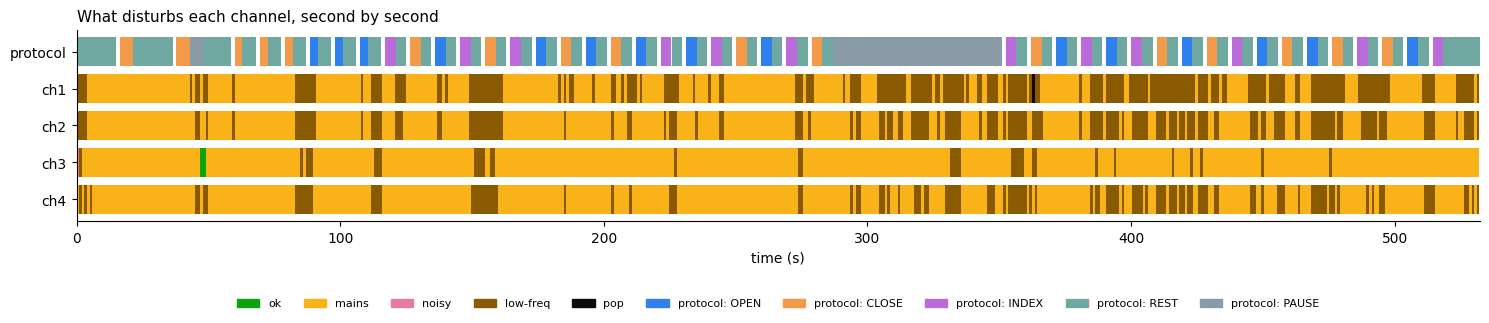

,ch1,ch2,ch3,ch4
ok,0.0,0.0,0.4,0.0
mains,58.0,67.9,92.9,76.4
noisy,0.0,0.0,0.2,0.0
low-freq,41.8,32.1,6.6,23.6
pop,0.2,0.0,0.0,0.0


In [33]:
sq.plot_timeline(rep)
plt.show()
counts = pd.DataFrame({ch: pd.Series(rep.win.cls[:, c]).value_counts(normalize=True) * 100
                       for c, ch in enumerate(rec.channels)}).fillna(0).round(1)
counts.reindex([k for k in sq.WINDOW_CLASSES if k in counts.index])   # % of the windows

## 8. Verdict and what to do

One row per channel with its status and every problem found, then the advice, the most serious
first. The session verdict is BAD when the link is bad or at least half of the channels are bad,
WARN when anything is flagged, GOOD otherwise.

In [34]:
print(f"VERDICT: {rep.verdict} - {rep.verdict_text}   (link: {rep.link['status']})")
with pd.option_context("display.max_colwidth", None):
    display(rep.channels[["channel", "status", "problems"]])
for grade, where, text in sq.advice(rep):
    print(f"[{grade}] {where}:\n    {text}\n")

VERDICT: BAD - poor stream: fix the setup before recording more   (link: GOOD)


,channel,status,problems
0,ch1,BAD,baseline wander 1215 µV; 50 Hz at rest 1236.2 µV RMS; noise floor at rest 25.7 µV RMS; 1-15 Hz at rest 324.3 µV RMS; weak EMG: best gesture CLOSE only 0.6x rest; correlated with ch2 at rest (r = -0.92); correlated with ch4 at rest (r = -0.94)
1,ch2,BAD,baseline wander 2027 µV; 50 Hz at rest 1063.4 µV RMS; noise floor at rest 20.5 µV RMS; 1-15 Hz at rest 233.1 µV RMS; weak EMG: best gesture CLOSE only 0.6x rest; correlated with ch1 at rest (r = -0.92); correlated with ch4 at rest (r = 0.91)
2,ch3,BAD,baseline wander 1838 µV; 50 Hz at rest 89.8 µV RMS; noise floor at rest 12.6 µV RMS; 1-15 Hz at rest 50.6 µV RMS; weak EMG: best gesture OPEN only 2.8x rest
3,ch4,BAD,baseline wander 1388 µV; 50 Hz at rest 621.4 µV RMS; noise floor at rest 13.4 µV RMS; 1-15 Hz at rest 144.8 µV RMS; weak EMG: best gesture OPEN only 1.1x rest; correlated with ch1 at rest (r = -0.94); correlated with ch2 at rest (r = 0.91)


[BAD] ch1, ch2, ch3, ch4:
    Mains (50 Hz): the two electrodes of this pair see different impedances, which turns common-mode mains into signal. Check the BIAS (reference) electrode first, re-prepare the skin of this pair, keep the cables short and together, keep away from power supplies, run the laptop on battery. (The notch removes 50 Hz offline, but a large mains level means poor contact.)

[BAD] ch1, ch2, ch3, ch4:
    High noise floor at rest: poor contact, or the subject is not fully relaxed. Re-seat the electrodes and ask the subject to let the arm rest completely.

[BAD] ch1, ch2, ch3, ch4:
    Low-frequency artifacts at rest (1-15 Hz): movement or cable sway. Support the arm, tape the cables down.

[BAD] ch1, ch2, ch3, ch4:
    Weak EMG: the gestures barely raise this channel above rest. Check that the electrodes lie over an active muscle (a channel may legitimately stay quiet for some gestures).

[WARN] ch1, ch2, ch3, ch4:
    Baseline wander: slow drifts (movement, sweat, c

## 9. Zoom

Set a time window (seconds from the start of the recording, as on the plots above) to look at
a stretch in detail, e.g. a pop or the moment a channel went noisy. `SCALE_UV` fixes the
vertical scale (`None` = automatic).

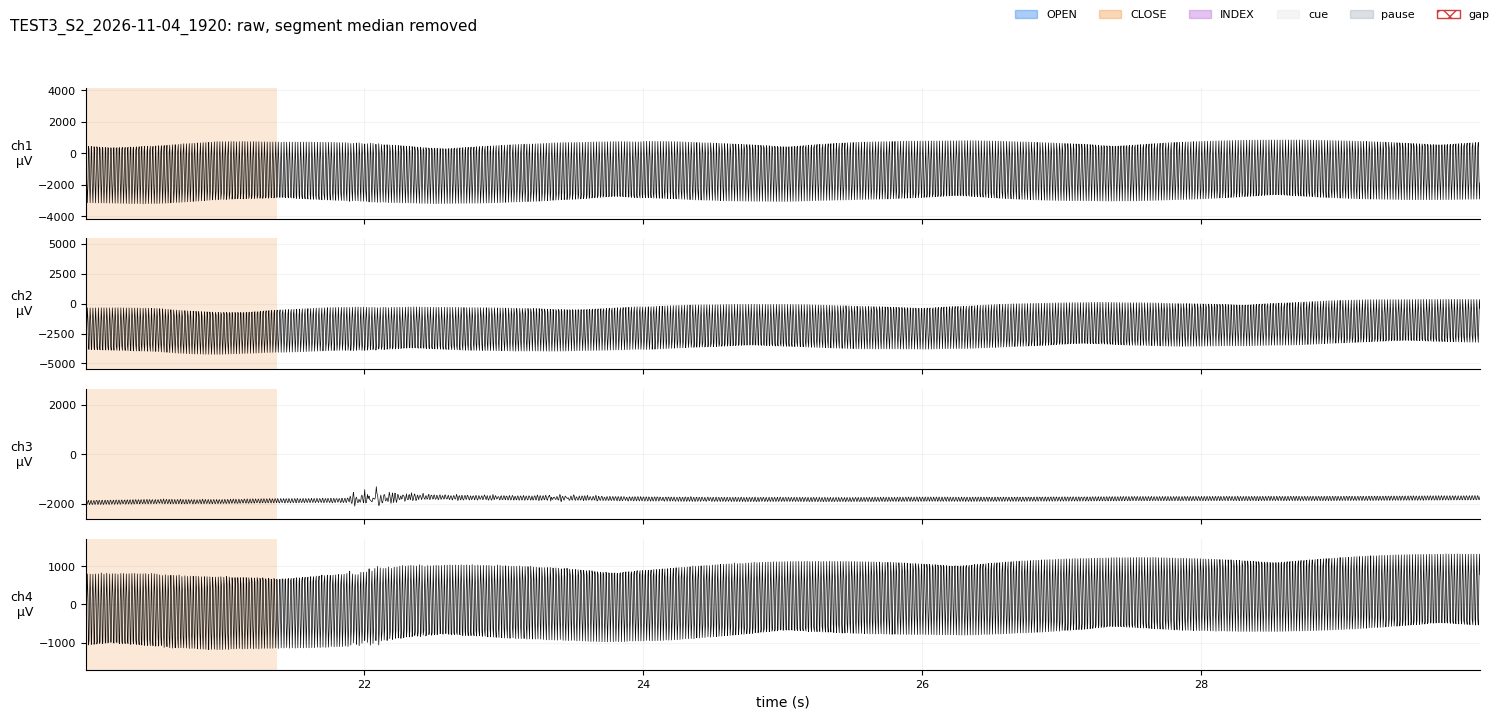

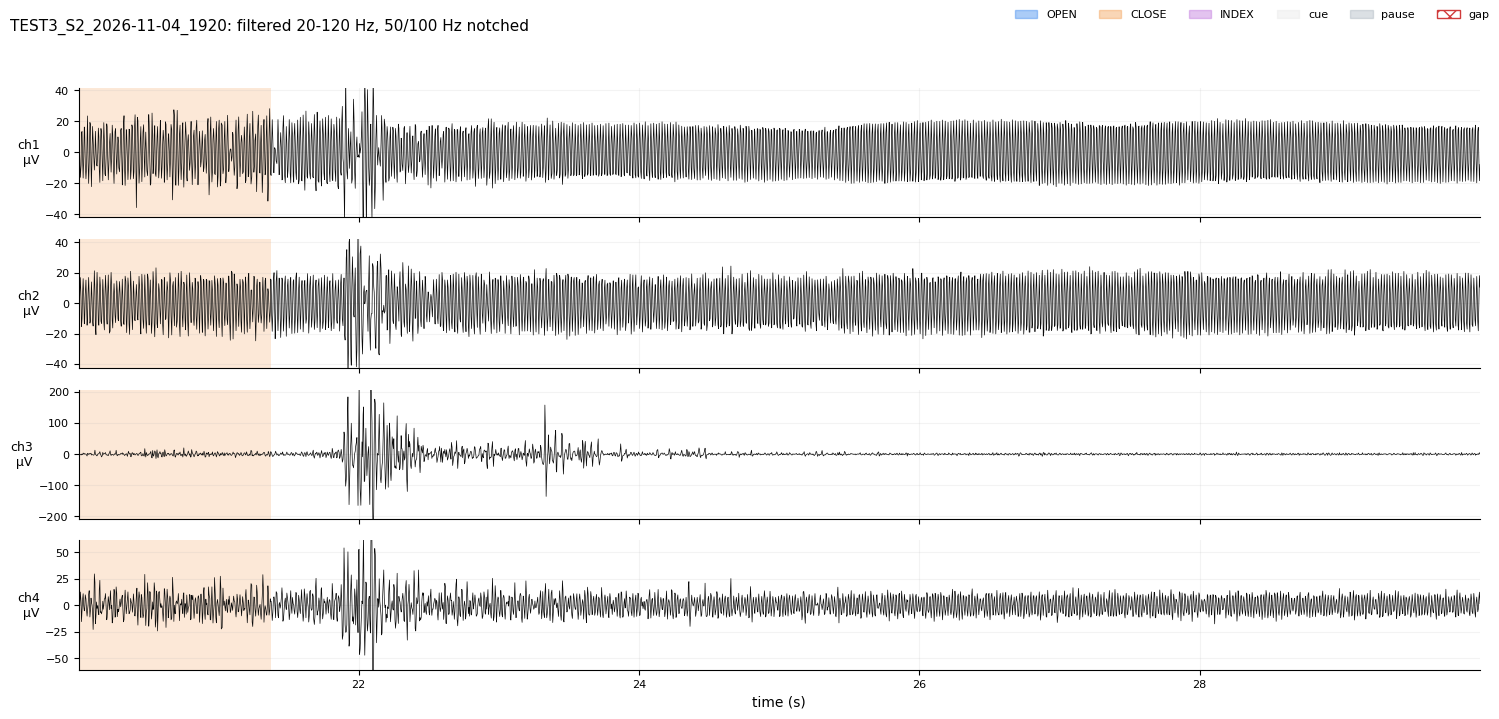

In [35]:
T0, T1 = 20.0, 30.0
SCALE_UV = None

sq.plot_signals(rec, "raw", T0, T1, SCALE_UV)
plt.show()
sq.plot_signals(rec, "emg", T0, T1, SCALE_UV)
plt.show()

## 10. Compare the sessions

One line per session in `data/` (the last 12): verdict, link, and per channel the status with
the rest noise floor (`n`, µV) and the 50 Hz level at rest (`m`, µV). Useful to see whether a
change in the setup (new electrodes, re-prepared skin, laptop on battery) actually helped.

In [36]:
pd.DataFrame([sq.summary_row(f, THRESHOLDS) for f in sessions[-12:]])

,session,verdict,status,mode,duration_s,loss_pct,gaps,zero_rows,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8
0,DEMO_S1_2026-10-01_2138,GOOD,completed,protocol,523.3,0.098,0,0,GOOD n1 m0,GOOD n1 m0,GOOD n1 m0,GOOD n1 m0,GOOD n1 m0,GOOD n1 m0,GOOD n1 m0,GOOD n1 m0
1,TEST_S1_2026-10-21_1650,BAD,aborted,protocol,173.2,0.000,1,1,BAD n13 m14,BAD n18 m33,WARN n9 m2,BAD n13 m133,NaN,NaN,NaN,NaN
2,TEST_S1_2026-10-21_1707,BAD,aborted,protocol,148.4,0.000,0,0,BAD n4 m59,WARN n5 m9,BAD n11 m8,WARN n1 m17,NaN,NaN,NaN,NaN
3,TEST_S1_2026-10-21_1747,BAD,aborted,protocol,80.1,0.000,0,0,WARN n8 m8,BAD n4 m115,BAD n13 m82,WARN n3 m37,NaN,NaN,NaN,NaN
4,TEST_S1_2026-10-21_1756,BAD,aborted,protocol,158.9,0.000,1,1,WARN n5 m6,BAD n2 m78,BAD n8 m56,WARN n4 m38,NaN,NaN,NaN,NaN
5,TEST_S1_FREE_2026-10-28_1900,BAD,completed,free,59.9,0.000,0,0,BAD n8 m422,BAD n3 m54,BAD n3 m185,BAD n10 m454,NaN,NaN,NaN,NaN
6,TEST_S2_FREE_2026-11-04_1850,BAD,completed,free,119.9,0.000,0,0,BAD n8 m587,BAD n10 m1054,WARN n9 m36,BAD n5 m162,NaN,NaN,NaN,NaN
7,TEST2_S2_2026-11-04_1854,BAD,completed,protocol,599.8,0.000,0,0,BAD n14 m736,BAD n15 m954,BAD n10 m64,BAD n7 m179,NaN,NaN,NaN,NaN
8,TEST3_S2_2026-11-04_1920,BAD,completed,protocol,532.4,0.000,0,0,BAD n26 m1236,BAD n21 m1063,BAD n13 m90,BAD n13 m621,NaN,NaN,NaN,NaN
